In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Is dataset me encoding issue hota hai, isliye latin-1 use karo
df = pd.read_csv("sales_data_sample.csv", encoding="latin-1")

print(df.head())
print(df.info())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
cols = ["SALES", "QUANTITYORDERED", "PRICEEACH"]

stats = df[cols].agg(["sum", "mean", "max", "min"])
print("=== Basic Statistics ===")
print(stats)

=== Basic Statistics ===
             SALES  QUANTITYORDERED      PRICEEACH
sum   1.003263e+07     99067.000000  236168.070000
mean  3.553889e+03        35.092809      83.658544
max   1.408280e+04        97.000000     100.000000
min   4.821300e+02         6.000000      26.880000


In [5]:
category_sales = df.groupby("PRODUCTLINE")["SALES"].sum().sort_values(ascending=False)
print(category_sales)

PRODUCTLINE
Classic Cars        3919615.66
Vintage Cars        1903150.84
Motorcycles         1166388.34
Trucks and Buses    1127789.84
Planes               975003.57
Ships                714437.13
Trains               226243.47
Name: SALES, dtype: float64


C:\Users\DELL PC\AppData\Local\Temp\ipykernel_10248\616312115.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_sales.index, y=category_sales.values, palette="viridis")


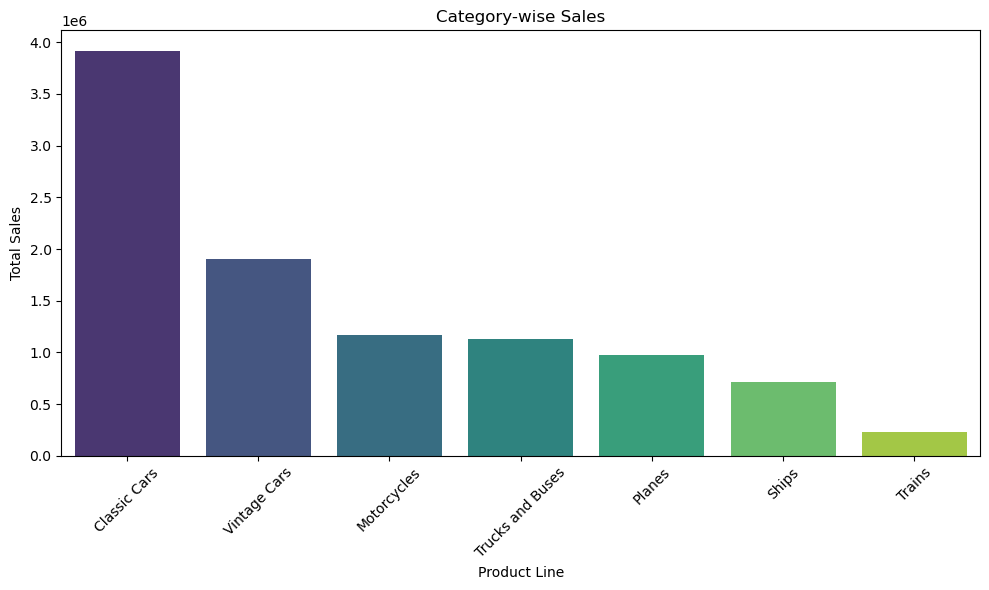

In [6]:
plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales.index, y=category_sales.values, palette="viridis")
plt.title("Category-wise Sales")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("category_bar.png")
plt.show()

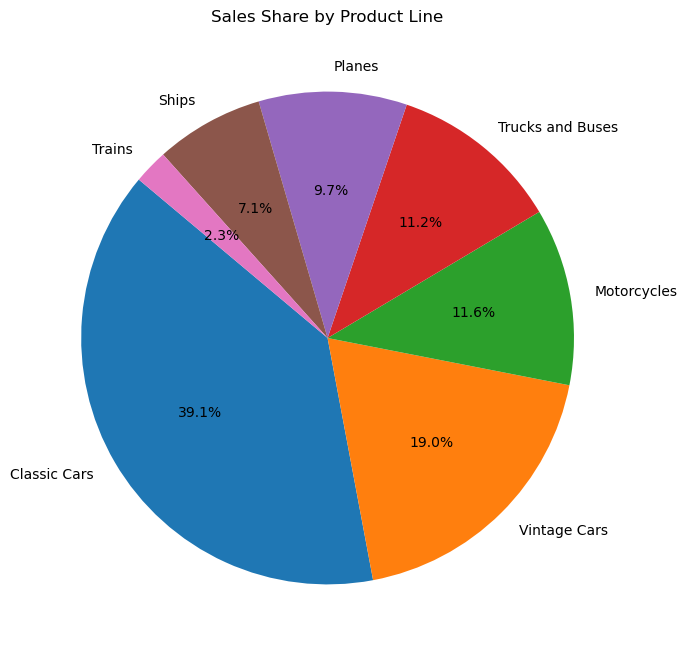

In [7]:
plt.figure(figsize=(8, 8))
plt.pie(category_sales.values, labels=category_sales.index,
        autopct="%1.1f%%", startangle=140)
plt.title("Sales Share by Product Line")
plt.savefig("category_pie.png")
plt.show()

In [8]:
# Top 5 products
top_products = df.groupby("PRODUCTCODE")["SALES"].sum().nlargest(5)
print("=== Top 5 Products ===")
print(top_products.round(2))

# Top 5 countries (region)
top_regions = df.groupby("COUNTRY")["SALES"].sum().nlargest(5)
print("=== Top 5 Countries ===")
print(top_regions.round(2))

=== Top 5 Products ===
PRODUCTCODE
S18_3232    288245.42
S10_1949    191073.03
S10_4698    170401.07
S12_1108    168585.32
S18_2238    154623.95
Name: SALES, dtype: float64
=== Top 5 Countries ===
COUNTRY
USA          3627982.83
Spain        1215686.92
France       1110916.52
Australia     630623.10
UK            478880.46
Name: SALES, dtype: float64


In [10]:
print("Thank you")

Thank you
